# step5_rerank_mmr

**Owner:** P6  
**Purpose:** Tune MMR to make KLAR's top 10 more varied, then evaluate the chosen setting on Test.  
**Inputs:** Step 1 candidate lists and article metadata, plus Step 4 KLAR scores and article vectors.  
**Outputs:** Ranked candidate files for Step 6, result tables, one tuning figure, and an example slate.

Run the Colab setup, then run Sections 1–4 in order.

In [1]:
# --- Colab setup: mount Drive and configure the shared project paths. ---
from copy import deepcopy
import json
import os
from pathlib import Path
from platform import python_version
import subprocess
import sys

from google.colab import drive
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

drive.mount("/content/drive")

# Choose the first shortcut that contains the processed datasets.
drive_shortcuts = (
    Path("/content/drive/MyDrive/BT4222_Project"),
    Path("/content/drive/MyDrive/BT4222 G4/BT4222_Project"),
)
data_root = next(
    (folder for folder in drive_shortcuts if (folder / "data" / "processed").is_dir()),
    None,
)
if data_root is None:
    raise FileNotFoundError(
        "No BT4222_Project shortcut with data/processed was found in MyDrive "
        "or MyDrive/BT4222 G4."
    )
os.environ["MIND_PROJECT_DIR"] = str(data_root)

# Load the repository helpers with the Drive path already set for config.
project_root = Path("/content/BT4222-Project-Group-4--MIND")
if not (project_root / "config.py").is_file():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/Fdiannz/BT4222-Project-Group-4--MIND.git",
            str(project_root),
        ],
        check=True,
    )
sys.path.insert(0, str(project_root))

# Import project modules after configuring Drive and the checkout path.
import config
from utils.metrics import _per_impression, add_rank, attach_scores, label_impression_segment, topk

print("Data folder:", config.DATA_DIR)
print("Processed folder:", config.PROCESSED_DIR)

Mounted at /content/drive
Data folder: /content/drive/MyDrive/BT4222_Project/data
Processed folder: /content/drive/MyDrive/BT4222_Project/data/processed


## 1. Inputs, relevance baseline, and MMR implementation

Build the original KLAR ranking, then use article similarity to reduce repetition in the top 10.

### 1.1 Input paths and settings

The notebook uses the KLAR v1 Tune and Test scores from Step 4. The matching article vectors and article IDs let MMR compare stories. Shared settings and file locations come from `config`.

In [2]:
# --- 1.1a: Configure candidate paths and shared settings. ---

# The Colab setup points config to the shared Drive folder.
TUNE_CANDIDATES_PATH = Path(config.PROCESSED_DIR) / "tune_candidates.parquet"
EVAL_CANDIDATES_PATH = Path(config.PROCESSED_DIR) / "eval_candidates.parquet"
KEY_COLUMNS = ["impression_id", "news_id"]
COLD_COLUMN = "cold_article"
# Keep every candidate row, but load only the fields consumed by reranking and evaluation.
CANDIDATE_COLUMNS = KEY_COLUMNS + ["label", COLD_COLUMN, "category"]
TOP_K, SEED = config.TOP_K, config.SEED
LAMBDA_VALUES = tuple(config.MMR_LAMBDAS)
INPUT_SPLITS = {"tune": TUNE_CANDIDATES_PATH, "eval": EVAL_CANDIDATES_PATH}
print("Top k:", TOP_K, "| Seed:", SEED, "| Lambda grid:", LAMBDA_VALUES)

Top k: 10 | Seed: 42 | Lambda grid: (1.0, 0.9, 0.8, 0.7, 0.6, 0.5)


In [3]:
# --- 1.1b: Configure the delivered KLAR scores, article vectors and provenance. ---
# Build paths from config; subsequent cells do not use local Windows paths.
# Both score splits and the article vectors come from the Step 4 KLAR v1 run.
BASE_MODEL_NAME = "klar_v1"
TUNE_SCORES_PATH = Path(config.SCORES_DIR) / "step4_klar_tune.parquet"
EVAL_SCORES_PATH = Path(config.SCORES_DIR) / "step4_klar_eval.parquet"
SCORE_COLUMN = "score"
# P5 exports vectors as NumPy, aligned article IDs as Parquet, and provenance as JSON.
NEWS_EMBEDDINGS_PATH = Path(config.DATA_DIR) / "embeddings" / "step4_klar_news_vectors.npy"
NEWS_EMBEDDING_IDS_PATH = Path(config.DATA_DIR) / "embeddings" / "step4_klar_news_ids.parquet"
NEWS_EMBEDDINGS_METADATA_PATH = Path(config.DATA_DIR) / "embeddings" / "step4_klar_news_vectors.json"
EMBEDDING_ENCODER_ID = "klar_v1:news_representation"
RELEVANCE_SCALING = "per_impression_minmax"  # Balance within-slate scores against cosine similarity.

# These paths resolve through either setup; Section 2.4 applies the tuning selection rule.
print("Model:", BASE_MODEL_NAME, "| Encoder:", EMBEDDING_ENCODER_ID)
print("Tuning scores:", TUNE_SCORES_PATH, "| Evaluation scores:", EVAL_SCORES_PATH)

Model: klar_v1 | Encoder: klar_v1:news_representation
Tuning scores: /content/drive/MyDrive/BT4222_Project/data/scores/step4_klar_tune.parquet | Evaluation scores: /content/drive/MyDrive/BT4222_Project/data/scores/step4_klar_eval.parquet


### 1.2 Load processed candidates, model scores, and article vectors

Use the complete lists of articles shown in each Tune impression.

#### 1.2.1 Define input readers

Check that every candidate has one usable KLAR score.

In [4]:
# --- 1.2.1: Read processed candidates and join separately delivered scores. ---
def load_candidate_split(split):
    """Read the full processed split; cleaning and slate construction belong upstream."""
    return pd.read_parquet(INPUT_SPLITS[split], columns=CANDIDATE_COLUMNS, engine="pyarrow")


def load_scored_split(split, candidates):
    """Attach one original score per candidate using the shared strict join."""
    path = TUNE_SCORES_PATH if split == "tune" else EVAL_SCORES_PATH
    scores = pd.read_parquet(path, columns=KEY_COLUMNS + [SCORE_COLUMN], engine="pyarrow")
    scores = scores.rename(columns={SCORE_COLUMN: "score"})
    # This score artifact is separate from the already-cleaned candidate table.
    if not np.isfinite(scores["score"].to_numpy(dtype=np.float64)).all():
        raise ValueError("Model scores must be finite.")
    return attach_scores(candidates, scores)

#### 1.2.2 Load complete tuning candidates

Load all candidates shown on the tuning day.

In [5]:
# --- 1.2.2: Load complete tuning candidates without resampling/re-cleaning. ---
tune_candidates = load_candidate_split("tune")
print("Tuning rows:", len(tune_candidates), "| Impressions:", tune_candidates["impression_id"].nunique())
print(tune_candidates.head(5).to_string(index=False))

Tuning rows: 17400106 | Impressions: 431517
impression_id news_id  label  cold_article      category
       612270 N123683      0             0     lifestyle
       612270 N108269      0             0          news
       612270 N120332      0             0          news
       612270  N18405      0             0          news
       612270  N51569      0             0 entertainment


#### 1.2.3 Attach tuning model scores

Match KLAR scores to candidates by impression ID and article ID.

In [6]:
# --- 1.2.3: Attach tuning scores and inspect their original range. ---
tune_scored = load_scored_split("tune", tune_candidates)
del tune_candidates  # The joined table now contains every required candidate field.
print(tune_scored[KEY_COLUMNS + ["score"]].head(5).to_string(index=False))
print("Score range:", tune_scored["score"].min(), "to", tune_scored["score"].max())

impression_id news_id     score
       612270 N123683 -0.803735
       612270 N108269  0.446565
       612270 N120332  2.460759
       612270  N18405  1.050673
       612270  N51569 -0.691826
Score range: -6.82451868057251 to 9.077537536621094


#### 1.2.4 Load and normalize article embeddings

Match each article ID to its vector. Scale the vectors to unit length so their dot product gives cosine similarity, a measure of how similar two articles are in KLAR's representation.

In [7]:
# --- 1.2.4a: Build a keyed, normalized article-vector lookup. ---
def build_embedding_lookup(vectors, news_ids):
    """Check the new artifact's alignment and normalize vectors for cosine similarity."""
    values = np.asarray(vectors, dtype=np.float64)
    ids = np.asarray(news_ids)
    if values.ndim != 2 or ids.ndim != 1 or len(ids) != len(values) or values.size == 0:
        raise ValueError("Embeddings need a nonempty matrix and one news ID per row.")
    if pd.isna(ids).any() or pd.Index(ids).has_duplicates:
        raise ValueError("Embedding article IDs must be nonmissing and unique.")
    norms = np.linalg.norm(values, axis=1)
    if not np.isfinite(values).all() or not np.isfinite(norms).all() or (norms <= 0).any():
        raise ValueError("Cosine embeddings must be finite and nonzero.")
    return dict(zip(ids, (values / norms[:, None]).astype(np.float32)))


def require_embedding_coverage(candidates, lookup, split):
    """Check the separately supplied catalog covers every article in this split."""
    missing = pd.Index(candidates["news_id"].unique()).difference(lookup)
    if len(missing):
        raise ValueError(f"{split}: {len(missing)} articles lack vectors; examples: {missing[:5].tolist()}")
    print(f"{split}: all candidate articles have vectors.")


def load_article_embeddings(vector_path, ids_path):
    """Load P5's vector matrix and its row-aligned Parquet article IDs."""
    # Preserve exported ID order; never sort or join against the separate news metadata.
    news_ids = pd.read_parquet(ids_path, columns=["news_id"], engine="pyarrow")["news_id"].to_numpy()
    return build_embedding_lookup(np.load(vector_path, allow_pickle=False), news_ids)

In [8]:
# --- 1.2.4b: Load the article catalog and check tuning coverage once. ---

# Both splits use this catalog and the same upstream encoder. The loader normalizes raw vectors.
emb_lookup = load_article_embeddings(NEWS_EMBEDDINGS_PATH, NEWS_EMBEDDING_IDS_PATH)
require_embedding_coverage(tune_scored, emb_lookup, "tune")
# Retain the supplied epoch/training/source details for all later experiment exports.
with NEWS_EMBEDDINGS_METADATA_PATH.open("r", encoding="utf-8") as metadata_file:
    embedding_provenance = json.load(metadata_file)
# Check the model label recorded in the delivered embedding provenance.
if embedding_provenance["model"] != BASE_MODEL_NAME:
    raise ValueError(f"Expected {BASE_MODEL_NAME} article vectors, got {embedding_provenance['model']}.")
print("Loaded article vectors:", len(emb_lookup))
print("Embedding provenance:", embedding_provenance)

tune: all candidate articles have vectors.
Loaded article vectors: 104151
Embedding provenance: {'model': 'klar_v1', 'epoch': 5, 'trained_on': 'fit 9-13 Nov', 'dim': 256, 'n_articles': 104151, 'normalised': False, 'source': 'KLAR news representation: averaged word2vec title words (fine-tuned), category and category_subcategory embeddings, confidence-weighted TransE entity embedding, fused by a linear layer', 'row_order': 'same as step4_klar_news_ids.parquet'}


### 1.3 Relevance-only baseline

Use the original KLAR order as the reference for relevance, variety, and cold exposure.

#### 1.3.1 Construct the original ranking and define eligibility

Rank each impression by KLAR score, with a fixed seed for ties. MMR changes lists with more than ten candidates. Shorter lists and lists with exactly ten candidates keep their KLAR order.

In [9]:
# --- 1.3.1a: Build a reproducible relevance-only reference from joined model scores. ---
def build_relevance_reference(scored, k=None, seed=None):
    """Return complete ranks, slate eligibility, and top-k lists from Section 1.2 inputs."""
    # Use the shared top-k and seed when the caller leaves them unspecified.
    k = TOP_K if k is None else k
    seed = SEED if seed is None else seed
    required = KEY_COLUMNS + ["label", COLD_COLUMN, "category", "score"]

    # Canonical ordering makes seeded tie draws independent of input row order.
    # Keep only the fields needed downstream to limit extra copies of the large table.
    canonical = scored[required].sort_values(KEY_COLUMNS, kind="stable").reset_index(drop=True)
    ranked = add_rank(canonical, "score", rank_col="baseline_rank", seed=seed)
    del canonical

    # Determine eligibility from the full slate, never from a truncated top-k list.
    slates = ranked.groupby("impression_id", sort=False).size().rename("n_candidates").to_frame()
    slates["rerank_eligible"] = slates["n_candidates"].gt(k)
    ranked["rerank_eligible"] = ranked["impression_id"].map(slates["rerank_eligible"])

    # Pre-filter by known rank before using the shared top-k helper to avoid sorting
    # millions of candidates that cannot appear in the displayed reference lists.
    top = topk(ranked.loc[ranked["baseline_rank"].le(k)], "baseline_rank", k=k)
    return ranked, slates, top

In [10]:
# --- 1.3.1b: Build the deterministic baseline and inspect eligibility. ---
baseline_ranked, baseline_slates, baseline_top = build_relevance_reference(tune_scored, k=TOP_K, seed=SEED)
del tune_scored  # The baseline retains every field needed by ranking and metrics.
print("Eligible slates:", int(baseline_slates["rerank_eligible"].sum()))
print(baseline_top.head(10).to_string(index=False))

Eligible slates: 337656
impression_id news_id  label  cold_article  category    score  baseline_rank  rerank_eligible
      1000000  N63165      1             0     music 2.410128              1             True
      1000000 N122150      0             0    travel 1.868906              2             True
      1000000  N18168      0             0    sports 1.416386              3             True
      1000000  N79233      0             0 lifestyle 1.171908              4             True
      1000000  N76610      0             0     music 1.107424              5             True
      1000000  N14675      0             0    health 1.100767              6             True
      1000000 N102499      0             0     music 1.082156              7             True
      1000000  N48015      0             0     video 1.075964              8             True
      1000000  N48758      0             1    sports 1.055204              9             True
      1000000  N20250      0        

#### 1.3.2 Measure reference relevance overall and on eligible impressions

Measure MRR and nDCG from the article order. AUC uses the original KLAR scores. The relevance averages include impressions with at least one clicked and one unclicked article.

Report results for all impressions and for impressions eligible for MMR. Cold, warm, and mixed segments describe the articles clicked in each impression.

In [11]:
# --- 1.3.2a: Summarize an explicit ranking while retaining original-score AUC. ---
# P6 keeps full-precision aggregates; P2's default four-decimal summaries stay unchanged.
def p6_evaluate_by_segment_raw(frame, score_column, cold_column, seed):
    """Aggregate shared per-impression calculations without early rounding."""
    per = _per_impression(frame, score_column, "label", "impression_id", seed)
    per["segment"] = per["impression_id"].map(label_impression_segment(frame, cold_column))
    rows = {}
    for segment in ["all", "cold", "warm", "mixed"]:
        subset = per if segment == "all" else per.loc[per["segment"].eq(segment)]
        valid = subset.loc[subset["valid"]]
        row = valid[["auc", "mrr", "ndcg@5", "ndcg@10"]].mean().to_dict()
        row.update(n_impressions=int(len(valid)), n_skipped=int(len(subset) - len(valid)))
        rows[segment] = row
    result = pd.DataFrame.from_dict(rows, orient="index")
    result[["n_impressions", "n_skipped"]] = result[["n_impressions", "n_skipped"]].astype(np.int64)
    return result


def summarize_reference_relevance(ranked, rank_col="baseline_rank", seed=None):
    """Compare all/eligible full slates without recomputing tie-breaking per subset."""
    # Read the active seed at call time; explicit caller overrides still take priority.
    seed = SEED if seed is None else seed
    segments = ["all", "cold", "warm", "mixed"]
    metric_columns = ["model_score_auc", "mrr", "ndcg@5", "ndcg@10"]
    tables = []
    for scope in ["all_impressions", "eligible_impressions"]:
        # Keep this projection small; model_score and explicit rank have distinct roles.
        selected = ranked if scope == "all_impressions" else ranked.loc[ranked["rerank_eligible"]]
        if selected.empty:
            summary = pd.DataFrame(np.nan, index=segments, columns=metric_columns)
            summary["n_impressions"] = 0
            summary["n_skipped"] = 0
        else:
            inputs = selected[["impression_id", "label", COLD_COLUMN, "score"]].copy()
            original = p6_evaluate_by_segment_raw(inputs, "score", COLD_COLUMN, seed=seed)

            # A negative final rank is unique within each impression: no new tie draw.
            inputs["_order_score"] = -selected[rank_col].to_numpy(dtype=np.float64)
            ordered = p6_evaluate_by_segment_raw(inputs, "_order_score", COLD_COLUMN, seed=seed)
            summary = ordered.drop(columns="auc")
            summary.insert(0, "model_score_auc", original["auc"])
        summary.index.name = "segment"
        tables.append(summary)
    return pd.concat(tables, keys=["all_impressions", "eligible_impressions"], names=["scope"])

In [12]:
# --- 1.3.2b: Measure relevance using the fixed baseline order. ---

# Original scores feed AUC; the fixed order feeds MRR/nDCG.
baseline_relevance = summarize_reference_relevance(baseline_ranked)
print(baseline_relevance.to_string(float_format=lambda value: f"{value:.4f}"))

                              model_score_auc    mrr  ndcg@5  ndcg@10  n_impressions  n_skipped
scope                segment                                                                   
all_impressions      all               0.6837 0.3180  0.3471   0.4080         431517          0
                     cold              0.6295 0.3847  0.4131   0.4666          98756          0
                     warm              0.7037 0.3159  0.3415   0.4035         289215          0
                     mixed             0.6737 0.1804  0.2342   0.3046          43546          0
eligible_impressions all               0.6914 0.2412  0.2574   0.3268         337656          0
                     cold              0.6523 0.2325  0.2310   0.3021          58399          0
                     warm              0.7038 0.2557  0.2706   0.3394         237238          0
                     mixed             0.6752 0.1711  0.2202   0.2898          42019          0


#### 1.3.3 Measure reference diversity and cold exposure

For each complete top-10 list, count the categories, average the cosine similarity between article pairs, and measure the share of cold articles. Report averages for all complete lists and for the subset eligible for MMR.

In [13]:
# --- 1.3.3a: Summarize full top-k lists with explicit scope and missing-vector status. ---
# Preserve the shared population/metric definitions while retaining unrounded means.
def p6_topk_diversity_raw(top, category_col="category", emb_lookup=None, news_col="news_id",
                          cold_col=None, group_col="impression_id", k=10):
    """Compute full-list metrics from the loaded article catalog without early rounding."""
    sizes = top.groupby(group_col, sort=False)[news_col].transform("size")
    full = top.loc[sizes.eq(k)].sort_values(group_col, kind="stable")
    result = {"unique_categories": float(full.groupby(group_col)[category_col].nunique().mean())}
    if emb_lookup is not None and k > 1:
        ids = pd.Index(full[news_col].unique())
        # Input vectors were checked at loading; normalize this compact metric matrix.
        vectors = np.stack([emb_lookup[news_id] for news_id in ids]).astype(np.float32)
        norms = np.linalg.norm(vectors, axis=1, keepdims=True)
        vectors /= norms
        positions = ids.get_indexer(full[news_col]).reshape(-1, k)
        similarity = np.empty(len(positions), dtype=np.float64)
        triangle = np.triu_indices(k, 1)
        for start in range(0, len(positions), 2048):
            block = vectors[positions[start:start + 2048]]
            cosine = np.clip(np.einsum("nkd,njd->nkj", block, block), -1.0, 1.0)
            similarity[start:start + 2048] = cosine[:, triangle[0], triangle[1]].mean(axis=1, dtype=np.float64)
        result["intra_list_sim"] = float(similarity.mean())
    if cold_col is not None:
        result["cold_share"] = float(full.groupby(group_col)[cold_col].mean().mean())
    result["n_lists"] = int(full[group_col].nunique())
    result["n_short_lists_excluded"] = int(top[group_col].nunique() - result["n_lists"])
    return result


def summarize_reference_diversity(top, lookup=None, k=None):
    """Use the shared full-list definition and handle empty scopes explicitly."""
    # Resolve k from current settings, rather than retaining the value at function definition.
    k = TOP_K if k is None else k
    rows = {}
    for scope in ["all_full_topk_lists", "eligible_impressions"]:
        selected = top if scope == "all_full_topk_lists" else top.loc[top["rerank_eligible"]]
        sizes = selected.groupby("impression_id", sort=False).size()
        n_full = int(sizes.eq(k).sum())
        if n_full == 0:
            result = {
                "unique_categories": np.nan, "intra_list_sim": np.nan, "cold_share": np.nan,
                "n_lists": 0, "n_short_lists_excluded": int(len(sizes)),
            }
            status = "NO_FULL_LISTS"
        else:
            result = p6_topk_diversity_raw(selected, category_col="category", emb_lookup=lookup,
                                    cold_col=COLD_COLUMN, k=k)
            if lookup is None:
                result["intra_list_sim"] = np.nan
                status = "EMBEDDINGS_NOT_PROVIDED"
            elif k == 1:
                result["intra_list_sim"] = np.nan
                status = "UNDEFINED_SINGLE_ITEM_LIST"
            else:
                status = "AVAILABLE"
        result["n_input_impressions"] = int(len(sizes))
        result["semantic_status"] = status
        rows[scope] = result
    result_table = pd.DataFrame.from_dict(rows, orient="index")
    result_table.index.name = "scope"
    return result_table

In [14]:
# --- 1.3.3b: Measure baseline diversity and cold exposure. ---

# Full-list metrics exclude short lists and retain their population counts.
baseline_diversity = summarize_reference_diversity(baseline_top, lookup=emb_lookup, k=TOP_K)
print(baseline_diversity.to_string(float_format=lambda value: f"{value:.4f}"))

                      unique_categories  intra_list_sim  cold_share  n_lists  n_short_lists_excluded  n_input_impressions semantic_status
scope                                                                                                                                    
all_full_topk_lists              5.5562          0.3101      0.2086   348203                   83314               431517       AVAILABLE
eligible_impressions             5.5191          0.3137      0.2054   337656                       0               337656       AVAILABLE


### 1.4 Greedy MMR implementation

MMR starts with KLAR's highest-ranked article. For each remaining slot in the top 10, it chooses the article with the best balance of relevance and novelty:

`lambda * relevance - (1 - lambda) * similarity to the closest article already chosen`

A smaller lambda gives more weight to avoiding similar stories. Lambda = 1 keeps the KLAR order.

#### 1.4.1 Relevance scaling and numerical conventions

Rescale KLAR scores from 0 to 1 within each impression so they can be combined with article similarity. If all scores are equal, their scaled relevance is zero. Near-ties in the MMR score follow the original KLAR order.

In [15]:
# --- 1.4.1: Validate lambda and scale a single slate's temporary relevance values. ---
def validate_mmr_lambda(value):
    """Keep the parameter within MMR's mathematical domain."""
    if not np.isfinite(value) or not 0 <= value <= 1:
        raise ValueError("MMR lambda must be finite and in [0, 1].")
    return float(value)


SUPPORTED_RELEVANCE_SCALING = ("none", "per_impression_minmax")
# One small absolute cosine band absorbs float32 accumulation noise for numerical ties.
# Its contribution to an MMR objective is scaled by that objective's diversity weight.
MMR_COSINE_TIE_ATOL = 1e-7
MMR_PROGRESS_EVERY = 50000  # Print progress per eligible slate; use 0 to disable.


def scale_mmr_relevance(scores, method):
    """Scale one complete slate without altering its original model scores."""
    # run_mmr_ranks validates the method once before processing impressions.
    values = np.array(scores, dtype=np.float64, copy=True)
    if method == "none":
        return values

    # Rescale by magnitude first so max-min cannot overflow on extreme finite logits.
    # Constant scores have no relevance preference; baseline rank resolves any ties.
    magnitude = np.max(np.abs(values))
    if magnitude == 0:
        return np.zeros_like(values)
    bounded = values / magnitude
    lo, hi = bounded.min(), bounded.max()
    if hi == lo:
        return np.zeros_like(values)
    return np.clip((bounded - lo) / (hi - lo), 0.0, 1.0)


print("Configured scaling:", RELEVANCE_SCALING)
print("First item and numerical MMR ties use baseline order; lambda=1 preserves the reference.")

Configured scaling: per_impression_minmax
First item and numerical MMR ties use baseline order; lambda=1 preserves the reference.


#### 1.4.2 Prepare arrays once for repeated MMR runs

Group each impression's candidates and article vectors so the tuning runs can share the same inputs.

In [16]:
# --- 1.4.2: Prepare grouping and vector arrays for repeated MMR calls. ---
def prepare_mmr_inputs(reference, lookup, k=None):
    """Cache arrays/indexes from the baseline and loaded article catalog."""
    k = TOP_K if k is None else k
    scores = reference["score"].to_numpy(dtype=np.float64, copy=True)
    ranks = reference["baseline_rank"].to_numpy(dtype=np.int64)
    group_codes, _ = pd.factorize(reference["impression_id"], sort=False)
    sizes = np.bincount(group_codes)
    starts = np.r_[0, np.cumsum(sizes)[:-1]]
    order = np.lexsort((ranks, group_codes))

    # Gather and normalize vectors once before the sweep.
    news_ids = pd.Index(reference["news_id"].unique())
    matrix = np.stack([lookup[news_id] for news_id in news_ids]).astype(np.float64)
    matrix = (matrix / np.linalg.norm(matrix, axis=1, keepdims=True)).astype(np.float32)
    prepared = {
        "reference": reference, "k": int(k), "scores": scores, "baseline_ranks": ranks,
        "order": order, "starts": starts, "ends": starts + sizes,
        "eligible_groups": sizes > k,
        "article_index": news_ids.get_indexer(reference["news_id"]).astype(np.int32),
        "embeddings": matrix,
    }
    return prepared

#### 1.4.3 Greedy selection and complete final order

After filling the top 10, append the remaining articles in their original KLAR order. This gives every candidate a final rank.

In [17]:
# --- 1.4.3a: Select a single eligible slate using incremental maximum similarity. ---
def _greedy_mmr_order(relevance, vectors, k, lambda_value):
    """Internal kernel: inputs are already sorted by baseline rank."""
    n = len(relevance)
    # Bound the tie band by cosine precision, not the magnitude of raw model scores.
    objective_tie_atol = (1.0 - lambda_value) * MMR_COSINE_TIE_ATOL
    selected = np.empty(k, dtype=np.int64)
    chosen = np.zeros(n, dtype=bool)

    # Seed with the baseline-best article: no selected set exists for a penalty yet.
    selected[0] = 0
    chosen[0] = True
    max_similarity = np.clip(vectors @ vectors[0], -1.0, 1.0).astype(np.float64)
    for step in range(1, k):
        objectives = lambda_value * relevance - (1.0 - lambda_value) * max_similarity
        objectives[chosen] = -np.inf

        # Identical vectors can differ by float32 round-off between matrix rows.
        # Among numerically tied objectives, take the first position in baseline order.
        best_objective = objectives.max()
        winner = int(np.flatnonzero(objectives >= best_objective - objective_tie_atol)[0])
        selected[step] = winner
        chosen[winner] = True
        if step < k - 1:
            new_similarity = np.clip(vectors @ vectors[winner], -1.0, 1.0)
            max_similarity = np.maximum(max_similarity, new_similarity)

    # Leave all unselected candidates in baseline order after the selected top-k.
    return np.r_[selected, np.flatnonzero(~chosen)]


def run_mmr_ranks(prepared, lambda_value, scaling=None, progress_every=0):
    """Return final ranks aligned to prepared reference rows; never modify inputs."""
    weight = validate_mmr_lambda(lambda_value)
    if scaling is not None and scaling not in SUPPORTED_RELEVANCE_SCALING:
        raise ValueError(f"Unknown relevance scaling: {scaling!r}.")
    result = prepared["baseline_ranks"].copy()

    # Preserve original order exactly even if score scaling would collapse tiny gaps.
    if weight == 1.0:
        return result
    if scaling is None:
        raise ValueError("Set RELEVANCE_SCALING explicitly before running lambda < 1.")

    # Short/equal-size slates retain their original ranks; only eligible groups run.
    eligible = np.flatnonzero(prepared["eligible_groups"])
    for completed, group in enumerate(eligible, start=1):
        start, end = prepared["starts"][group], prepared["ends"][group]
        positions = prepared["order"][start:end]
        relevance = scale_mmr_relevance(prepared["scores"][positions], scaling)
        vectors = prepared["embeddings"][prepared["article_index"][positions]]
        local_order = _greedy_mmr_order(relevance, vectors, prepared["k"], weight)
        result[positions[local_order]] = np.arange(1, len(positions) + 1)
        if progress_every and completed % progress_every == 0:
            print(f"MMR lambda={weight:g}: {completed:,}/{len(eligible):,} eligible slates processed.")
    if progress_every:
        print(f"MMR lambda={weight:g}: complete; {len(eligible):,} eligible slates processed.")
    return result

In [18]:
# --- 1.4.3b: Expose a DataFrame adapter for the existing relevance/diversity helpers. ---
def apply_mmr(prepared, lambda_value, scaling=None, progress_every=0):
    """Return one lambda's full result; keep original score and baseline rank columns."""
    final_ranks = run_mmr_ranks(prepared, lambda_value, scaling, progress_every)
    result = prepared["reference"].copy()
    result["rerank_rank"] = final_ranks
    result["rerank_score"] = -final_ranks

    # Keep experiment settings alongside the in-memory result; exports come later.
    result.attrs["mmr_settings"] = {
        "lambda": float(lambda_value),
        "relevance_scaling": scaling if float(lambda_value) < 1 else "identity (not applied)",
        "top_k": prepared["k"],
        "first_selection": "baseline rank 1",
        "tie_rule": "lowest baseline rank within the numerical objective tie band",
        "cosine_tie_atol": MMR_COSINE_TIE_ATOL,
        "objective_tie_atol": (1.0 - float(lambda_value)) * MMR_COSINE_TIE_ATOL,
        "similarity": "maximum signed cosine to already-selected articles",
        "tail_order": "baseline order of unselected candidates",
    }
    return result

#### 1.4.4 Prepare tuning arrays and check lambda = 1

Check that lambda = 1 reproduces every KLAR rank, including ties.

In [19]:
# --- 1.4.4: Prepare tuning arrays and verify the relevance-only identity. ---

# This assertion checks the algorithm identity rather than revalidating source rows.
mmr_prepared = prepare_mmr_inputs(baseline_ranked, emb_lookup, k=TOP_K)
np.testing.assert_array_equal(run_mmr_ranks(mmr_prepared, 1.0, RELEVANCE_SCALING),
                              baseline_ranked["baseline_rank"].to_numpy())
print("Lambda = 1 preserves the baseline order exactly.")

Lambda = 1 preserves the baseline order exactly.


## 2. Lambda sweep and tuning-only selection

Compare the tested lambda values on Tune. The choice balances category variety against the drop in nDCG@10.

### 2.1 Record tuning experiment settings

Use the same candidates, scores, and article vectors at every lambda.

In [20]:
# --- 2.1: Record the specification used by this tuning run. ---
tuning_settings = {
    "model": BASE_MODEL_NAME, "embedding_encoder_id": EMBEDDING_ENCODER_ID,
    "split": "tune", "tune_date": str(config.TUNE_DATE), "top_k": TOP_K, "seed": SEED,
    "lambdas": tuple(sorted({1.0, *(validate_mmr_lambda(v) for v in LAMBDA_VALUES)}, reverse=True)),
    "relevance_scaling": RELEVANCE_SCALING, "cold_column": COLD_COLUMN, "score_column": SCORE_COLUMN,
    "candidate_path": str(TUNE_CANDIDATES_PATH), "score_path": str(TUNE_SCORES_PATH),
    "embedding_path": str(NEWS_EMBEDDINGS_PATH), "embedding_ids_path": str(NEWS_EMBEDDING_IDS_PATH),
    "embedding_metadata_path": str(NEWS_EMBEDDINGS_METADATA_PATH),
    "embedding_provenance": deepcopy(embedding_provenance),
    "eligibility": "full slate size > top_k",
    "baseline_ties": "shared seeded ties after canonical candidate-key sorting",
    "mmr_ties": "lowest baseline rank within (1 - lambda) * mmr_cosine_tie_atol of the best objective",
    "mmr_cosine_tie_atol": MMR_COSINE_TIE_ATOL, "similarity": "maximum signed cosine",
}
# Scaling is a required experiment choice, rather than a guessed default.
if RELEVANCE_SCALING not in SUPPORTED_RELEVANCE_SCALING:
    raise ValueError(f"Set RELEVANCE_SCALING to one of {SUPPORTED_RELEVANCE_SCALING} in 1.1.")

### 2.2 Run the tuning lambda sweep

Measure each tuning ranking against the original KLAR order.

#### 2.2.1 Prepare reusable metric inputs

Calculate ranking metrics from each new order. Original-score AUC stays the same across settings.

In [21]:
# --- 2.2.1: Prepare the invariant article matrix and summarize explicit rank relevance. ---
def prepare_sweep_metric_context(reference, lookup, settings):
    """Cache only active vectors, normalized exactly as utils.metrics.topk_diversity."""
    ids = pd.Index(reference["news_id"].unique())
    matrix = np.stack([lookup[news_id] for news_id in ids]).astype(np.float32)
    matrix /= np.maximum(np.linalg.norm(matrix, axis=1, keepdims=True), 1e-12)
    return {"news_ids": ids, "vectors": matrix, "k": settings["top_k"],
            "seed": settings["seed"], "cold_column": settings["cold_column"]}


def summarize_sweep_relevance(ranked, rank_column, baseline_relevance, context):
    """Use shared ranking/segment metrics while reusing invariant original-score AUC."""
    tables = []
    for scope in ["all_impressions", "eligible_impressions"]:
        selected = ranked if scope == "all_impressions" else ranked.loc[ranked["rerank_eligible"]]
        if selected.empty:
            summary = baseline_relevance.loc[scope].copy()
        else:
            inputs = selected[["impression_id", "label", context["cold_column"]]].copy()
            inputs["_order_score"] = -selected[rank_column].to_numpy(dtype=np.float64)
            summary = p6_evaluate_by_segment_raw(inputs, "_order_score", context["cold_column"],
                                          seed=context["seed"]).drop(columns="auc")
            summary.insert(0, "model_score_auc", baseline_relevance.loc[scope, "model_score_auc"])
        summary.index.name = "segment"
        tables.append(summary)
    return pd.concat(tables, keys=["all_impressions", "eligible_impressions"], names=["scope"])

#### 2.2.2 Define full-list diversity metrics

Measure category variety, article similarity, and cold share across complete top-10 lists.

In [22]:
# --- 2.2.2: Compute full-list diversity with reusable vectors. ---
def summarize_sweep_diversity(top, context, semantic_batch_size=2048):
    """Match Section 1 diversity metrics without repeatedly stacking the lookup."""
    k = context["k"]
    rows = {}
    for scope in ["all_full_topk_lists", "eligible_impressions"]:
        selected = top if scope == "all_full_topk_lists" else top.loc[top["rerank_eligible"]]
        sizes = selected.groupby("impression_id", sort=False).size()
        if not sizes.eq(k).any():
            result = {"unique_categories": np.nan, "intra_list_sim": np.nan, "cold_share": np.nan,
                      "n_lists": 0, "n_short_lists_excluded": len(sizes)}
            status = "NO_FULL_LISTS"
        else:
            # Let the shared helper define category/cold-share means and exclusions.
            result = p6_topk_diversity_raw(selected, category_col="category", emb_lookup=None,
                                    cold_col=context["cold_column"], k=k)
            full = selected.loc[selected["impression_id"].isin(sizes.index[sizes.eq(k)])]
            full = full.sort_values("impression_id", kind="stable")
            indices = context["news_ids"].get_indexer(full["news_id"])
            if k == 1:
                result["intra_list_sim"] = np.nan
                status = "UNDEFINED_SINGLE_ITEM_LIST"
            else:
                indices = indices.reshape(-1, k)
                similarity = np.empty(len(indices), dtype=np.float64)
                triangle = np.triu_indices(k, 1)
                for start in range(0, len(indices), semantic_batch_size):
                    vectors = context["vectors"][indices[start:start + semantic_batch_size]]
                    cosine = np.clip(np.einsum("nkd,njd->nkj", vectors, vectors), -1.0, 1.0)
                    similarity[start:start + semantic_batch_size] = cosine[:, triangle[0], triangle[1]].mean(axis=1, dtype=np.float64)
                result["intra_list_sim"] = float(similarity.mean())
                status = "AVAILABLE"
        result["n_input_impressions"] = len(sizes)
        result["semantic_status"] = status
        rows[scope] = result
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "scope"
    return table[["unique_categories", "intra_list_sim", "cold_share", "n_lists",
                  "n_short_lists_excluded", "n_input_impressions", "semantic_status"]]

#### 2.2.3 Execute the full sweep

Run each lambda on the same tuning impressions. Lambda = 1 supplies the baseline.

In [23]:
# --- 2.2.3: Run the tuning sweep directly, retaining compact metric summaries. ---
metric_context = prepare_sweep_metric_context(baseline_ranked, emb_lookup, tuning_settings)
tuning_sweep_summaries = {}
for weight in tuning_settings["lambdas"]:
    if weight == 1.0:
        # The reference summaries already describe this exact order.
        relevance = baseline_relevance.copy()
        diversity = baseline_diversity.copy()
    else:
        ranked = apply_mmr(mmr_prepared, weight, RELEVANCE_SCALING, MMR_PROGRESS_EVERY)
        relevance = summarize_sweep_relevance(ranked, "rerank_rank", baseline_relevance, metric_context)
        ranked_top = topk(ranked.loc[ranked["rerank_rank"].le(TOP_K)], "rerank_rank", k=TOP_K)
        diversity = summarize_sweep_diversity(ranked_top, metric_context)
        del ranked, ranked_top  # Retain summaries, not a full candidate table per lambda.
    tuning_sweep_summaries[weight] = {"relevance": relevance, "diversity": diversity}
    print(f"Completed tuning metrics for lambda={weight:g}.")
del metric_context

Completed tuning metrics for lambda=1.
MMR lambda=0.9: 50,000/337,656 eligible slates processed.
MMR lambda=0.9: 100,000/337,656 eligible slates processed.
MMR lambda=0.9: 150,000/337,656 eligible slates processed.
MMR lambda=0.9: 200,000/337,656 eligible slates processed.
MMR lambda=0.9: 250,000/337,656 eligible slates processed.
MMR lambda=0.9: 300,000/337,656 eligible slates processed.
MMR lambda=0.9: complete; 337,656 eligible slates processed.
Completed tuning metrics for lambda=0.9.
MMR lambda=0.8: 50,000/337,656 eligible slates processed.
MMR lambda=0.8: 100,000/337,656 eligible slates processed.
MMR lambda=0.8: 150,000/337,656 eligible slates processed.
MMR lambda=0.8: 200,000/337,656 eligible slates processed.
MMR lambda=0.8: 250,000/337,656 eligible slates processed.
MMR lambda=0.8: 300,000/337,656 eligible slates processed.
MMR lambda=0.8: complete; 337,656 eligible slates processed.
Completed tuning metrics for lambda=0.8.
MMR lambda=0.7: 50,000/337,656 eligible slates proc

### 2.3 Assemble and inspect tuning comparisons

Compare each result with lambda = 1 on the same groups of impressions.

#### 2.3.1 Define raw comparison tables

Show the measured values and their changes from KLAR.

In [24]:
# --- 2.3.1: Define explicit missing/zero-reference handling for signed metric changes. ---
def _tuning_metric_change(value, reference):
    """Return signed delta, relative percent, and an explicit availability status."""
    if pd.isna(reference):
        return np.nan, np.nan, "MISSING_BASELINE"
    if pd.isna(value):
        return np.nan, np.nan, "MISSING_VALUE"
    delta = float(value) - float(reference)
    if reference == 0:
        return delta, np.nan, "ZERO_BASELINE"
    return delta, 100.0 * delta / abs(float(reference)), "AVAILABLE"


def build_tuning_comparison_tables(summaries, settings):
    """Assemble compact summaries without rerunning ranking or data loading."""
    grid = settings["lambdas"]
    relevance = pd.concat([summaries[w]["relevance"] for w in grid], keys=grid, names=["lambda"])
    diversity = pd.concat([summaries[w]["diversity"] for w in grid], keys=grid, names=["lambda"])
    rel_metrics = ["model_score_auc", "mrr", "ndcg@5", "ndcg@10"]
    div_metrics = ["unique_categories", "intra_list_sim", "cold_share"]
    rows = []
    for weight in grid:
        record = summaries[weight]
        row = {"lambda": weight, "model": settings["model"], "split": settings["split"],
               "top_k": settings["top_k"], "seed": settings["seed"],
               "relevance_scaling": settings["relevance_scaling"]}
        for (scope, segment), values in record["relevance"].iterrows():
            for metric in rel_metrics + ["n_impressions", "n_skipped"]:
                key = f"relevance__{scope}__{segment}__{metric}"
                row[key] = values[metric]
                if metric in rel_metrics:
                    baseline_value = summaries[1.0]["relevance"].loc[(scope, segment), metric]
                    delta, relative, status = _tuning_metric_change(values[metric], baseline_value)
                    row[key + "__delta"] = delta
                    row[key + "__relative_change_pct"] = relative
                    row[key + "__change_status"] = status
        for scope, values in record["diversity"].iterrows():
            for metric in div_metrics + ["n_lists", "n_short_lists_excluded", "n_input_impressions", "semantic_status"]:
                key = f"diversity__{scope}__{metric}"
                row[key] = values[metric]
                if metric in div_metrics:
                    baseline_value = summaries[1.0]["diversity"].loc[scope, metric]
                    delta, relative, status = _tuning_metric_change(values[metric], baseline_value)
                    row[key + "__delta"] = delta
                    row[key + "__relative_change_pct"] = relative
                    row[key + "__change_status"] = status
        rows.append(row)
    wide = pd.DataFrame(rows).set_index("lambda")

    # Retain counts as integers even though iterrows mixes them with floating metrics.
    count_columns = [c for c in wide.columns if c.endswith(("__n_impressions", "__n_skipped", "__n_lists",
                                                            "__n_short_lists_excluded", "__n_input_impressions"))]
    wide[count_columns] = wide[count_columns].astype(np.int64)
    wide.attrs["experiment_settings"] = deepcopy(settings)
    return wide, relevance, diversity

#### 2.3.2 Build and inspect comparisons

The tables show how relevance, variety, and cold exposure change across the tested values.

In [25]:
# --- 2.3.2: Build the unrounded comparison tables and print formatted views. ---
(tuning_results, tuning_relevance_comparison, tuning_diversity_comparison) = build_tuning_comparison_tables(tuning_sweep_summaries, tuning_settings)
# Printing changes only the display precision, not stored values.
print("Relevance by scope and clicked-article segment:")
print(tuning_relevance_comparison.to_string(float_format=lambda value: f"{value:.4f}"))
print("Diversity, cold exposure, and list populations:")
print(tuning_diversity_comparison.to_string(float_format=lambda value: f"{value:.4f}"))

Relevance by scope and clicked-article segment:
                                     model_score_auc    mrr  ndcg@5  ndcg@10  n_impressions  n_skipped
lambda scope                segment                                                                   
1.0    all_impressions      all               0.6837 0.3180  0.3471   0.4080         431517          0
                            cold              0.6295 0.3847  0.4131   0.4666          98756          0
                            warm              0.7037 0.3159  0.3415   0.4035         289215          0
                            mixed             0.6737 0.1804  0.2342   0.3046          43546          0
       eligible_impressions all               0.6914 0.2412  0.2574   0.3268         337656          0
                            cold              0.6523 0.2325  0.2310   0.3021          58399          0
                            warm              0.7038 0.2557  0.2706   0.3394         237238          0
                         

### 2.4 Select lambda from the tuning trade-off

On Tune, the curve showed no clear point where gaining more variety suddenly cost much more relevance. The choice therefore favoured the most categories within a 2% relative nDCG@10 loss.

#### 2.4.1 Build the selection table and plot

The plot shows nDCG@10 loss and the mean number of categories for impressions with more than ten candidates. Each point is a tested lambda.

In [26]:
# --- 2.4.1a: Define the tuning-only decision rule and build compact selection evidence. ---
FALLBACK_MAX_NDCG_LOSS_PCT = 2.0  # Relative percent, not an absolute nDCG drop.
REPORTING_SETTINGS = {
    "relevance_metric": "ndcg@10", "diversity_metric": "unique_categories",
    "scope": "eligible_impressions", "relevance_scope": "eligible_impressions",
    "diversity_scope": "eligible_impressions",
}
# Reuse measured summaries; this cell performs no new ranking or Test evaluation.
tuning_selection_table = pd.DataFrame.from_dict({
    weight: {
        "ndcg@10": summary["relevance"].loc[("eligible_impressions", "all"), "ndcg@10"],
        "unique_categories": summary["diversity"].loc["eligible_impressions", "unique_categories"],
    }
    for weight, summary in tuning_sweep_summaries.items()
}, orient="index").rename_axis("lambda").sort_index(ascending=False)
tuning_baseline_ndcg = tuning_selection_table.loc[1.0, "ndcg@10"]
tuning_selection_table["ndcg_loss_pct"] = (
    100.0 * (tuning_baseline_ndcg - tuning_selection_table["ndcg@10"]) / tuning_baseline_ndcg
)
tuning_selection_table["within_fallback_budget"] = (
    tuning_selection_table["ndcg_loss_pct"] <= FALLBACK_MAX_NDCG_LOSS_PCT
)
# Highest category variety wins within the tolerance; relevance and lambda resolve exact ties.
fallback_candidates = tuning_selection_table.loc[
    tuning_selection_table["within_fallback_budget"]
].reset_index().sort_values(
    ["unique_categories", "ndcg@10", "lambda"], ascending=False, kind="stable",
)
FALLBACK_LAMBDA = float(fallback_candidates.iloc[0]["lambda"])
print(tuning_selection_table.to_string(float_format=lambda value: f"{value:.4f}"))

        ndcg@10  unique_categories  ndcg_loss_pct  within_fallback_budget
lambda                                                                   
1.0      0.3268             5.5191         0.0000                    True
0.9      0.3250             5.7704         0.5478                    True
0.8      0.3215             6.0727         1.5982                    True
0.7      0.3151             6.4357         3.5673                   False
0.6      0.3043             6.8665         6.8823                   False
0.5      0.2884             7.3377        11.7250                   False


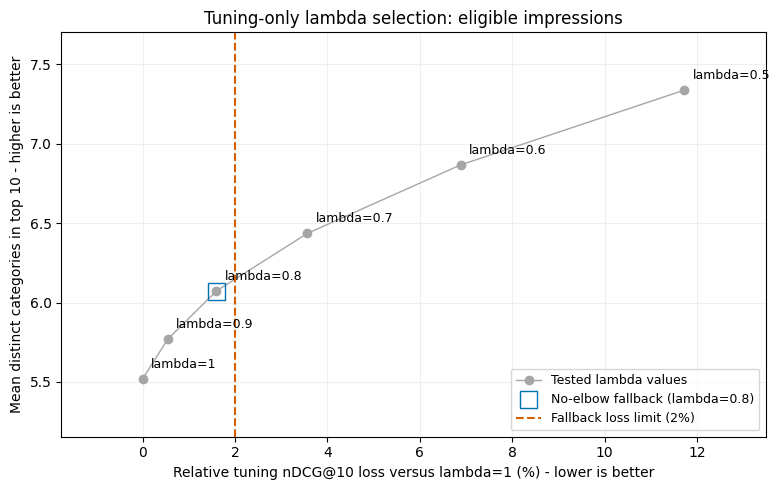

In [27]:
# --- 2.4.1b: Inspect category variety versus tuning relevance loss before choosing lambda. ---
tuning_selection_fig, tuning_selection_ax = plt.subplots(figsize=(8, 5))
# Connect in lambda order only; labels identify the measured operating points.
tuning_selection_ax.plot(
    tuning_selection_table["ndcg_loss_pct"], tuning_selection_table["unique_categories"],
    color="0.65", marker="o", linewidth=1, label="Tested lambda values",
)
for weight, point in tuning_selection_table.iterrows():
    tuning_selection_ax.annotate(
        f"lambda={weight:g}", (point["ndcg_loss_pct"], point["unique_categories"]),
        xytext=(6, 8), textcoords="offset points", fontsize=9,
    )
fallback_point = tuning_selection_table.loc[FALLBACK_LAMBDA]
tuning_selection_ax.scatter(
    [fallback_point["ndcg_loss_pct"]], [fallback_point["unique_categories"]],
    s=150, marker="s", facecolors="none", edgecolors="#0072B2",
    label=f"No-elbow fallback (lambda={FALLBACK_LAMBDA:g})", zorder=3,
)
tuning_selection_ax.axvline(
    FALLBACK_MAX_NDCG_LOSS_PCT, color="#D55E00", linestyle="--",
    label=f"Fallback loss limit ({FALLBACK_MAX_NDCG_LOSS_PCT:g}%)",
)
tuning_selection_ax.set(
    xlabel="Relative tuning nDCG@10 loss versus lambda=1 (%) - lower is better",
    ylabel=f"Mean distinct categories in top {TOP_K} - higher is better",
    title="Tuning-only lambda selection: eligible impressions",
)
tuning_selection_ax.grid(alpha=0.2)
tuning_selection_ax.margins(x=0.15, y=0.20)
tuning_selection_ax.legend(fontsize=9)
tuning_selection_fig.tight_layout()
plt.show()

#### 2.4.2 Fix lambda for held-out evaluation

The Tune results selected lambda = 0.8. Test uses that setting.

In [28]:
# --- 2.4.2: Fix the tuning-derived lambda and retain selection evidence. ---
SELECTED_LAMBDA = FALLBACK_LAMBDA
selection_method = "max_category_variety_within_tune_loss_budget"
selection_record = {
    "rule": "highest category variety within relative tuning nDCG@10 loss tolerance",
    "method": selection_method,
    "fallback_max_ndcg_loss_pct": FALLBACK_MAX_NDCG_LOSS_PCT,
    "fallback_lambda": FALLBACK_LAMBDA,
    "scope": "eligible_impressions", "relevance_metric": "ndcg@10",
    "diversity_metric": "unique_categories",
    "selected_tuning_metrics": tuning_selection_table.loc[
        SELECTED_LAMBDA, ["ndcg@10", "unique_categories", "ndcg_loss_pct"]
    ].to_dict(),
}
print(f"Selected lambda: {SELECTED_LAMBDA:g}")

Selected lambda: 0.8


### 2.5 Fix the tuning choice for evaluation

The chosen lambda and its Tune results carry forward to Test.

#### 2.5.1 Record selected settings and tuning evidence

Save the chosen setting and its measured Tune results.

In [29]:
# --- 2.5.1: Copy the tuning decision and its compact evidence. ---
selected_tuning_settings = {
    **deepcopy(tuning_settings), "lambda": SELECTED_LAMBDA,
    "selection_method": selection_method,
    "selection": deepcopy(selection_record),
    "reporting": deepcopy(REPORTING_SETTINGS),
}
selected_tuning_metrics = {
    "relevance": tuning_sweep_summaries[SELECTED_LAMBDA]["relevance"].copy(),
    "diversity": tuning_sweep_summaries[SELECTED_LAMBDA]["diversity"].copy(),
}
# The chosen setting is now fixed for the main held-out comparison.
print("Selected lambda:", SELECTED_LAMBDA)

Selected lambda: 0.8


#### 2.5.2 Release tuning candidate-level memory

Free the space used by the Tune rankings before loading Test.

In [30]:
# --- 2.5.2: Release tuning-only candidate tables and array cache. ---

# Compact metric tables and emb_lookup remain available for evaluation.
del baseline_ranked, baseline_top, baseline_slates, mmr_prepared
print("Tuning candidate tables/cache released; summaries and article catalog retained.")

Tuning candidate tables/cache released; summaries and article catalog retained.


## 3. Held-out evaluation: before versus after

Compare KLAR with KLAR + MMR on the 15 November Test split using the setting chosen on Tune.

### 3.1 Use the fixed tuning decision

Use the same model, settings, and ranking rules as Tune.

#### 3.1.1 Copy settings for held-out evaluation

Record the Test date and input files.

In [31]:
# --- 3.1.1: Carry the tuning-only decision straight into evaluation. ---
evaluation_settings = {
    **deepcopy(selected_tuning_settings), "split": "eval",
    "evaluation_date": str((pd.Timestamp(config.TUNE_DATE) + pd.Timedelta(days=1)).date()),
    "candidate_path": str(EVAL_CANDIDATES_PATH), "score_path": str(EVAL_SCORES_PATH),
}
# Show the held-out locations/date; model, lambda, scaling, and seed were already declared.
print(pd.Series({key: evaluation_settings[key] for key in
                 ["split", "evaluation_date", "candidate_path", "score_path"]}).to_string())

split                                                           eval
evaluation_date                                           2019-11-15
candidate_path     /content/drive/MyDrive/BT4222_Project/data/pro...
score_path         /content/drive/MyDrive/BT4222_Project/data/sco...


### 3.2 Load evaluation inputs

Load the full Test candidate lists and their KLAR scores.

#### 3.2.1 Load complete processed evaluation candidates

Keep every candidate shown in each Test impression.

In [32]:
# --- 3.2.1: Load and inspect the complete processed evaluation split. ---
eval_candidates = load_candidate_split("eval")
# These counts describe the population; upstream preprocessing owns data cleaning.
print("Evaluation rows:", len(eval_candidates), "| Impressions:", eval_candidates["impression_id"].nunique())
print(eval_candidates.head(5).to_string(index=False))

Evaluation rows: 14085557 | Impressions: 376471
impression_id news_id  label  cold_article  category
       359674  N98015      0             0     autos
       359674  N44109      0             0      news
       359674  N19586      0             0    health
       359674  N26122      0             0    sports
       359674 N109853      0             0 lifestyle


#### 3.2.2 Attach the selected model's evaluation scores

Match each Test candidate to its original KLAR score.

In [33]:
# --- 3.2.2: Attach original evaluation scores without retuning/rescaling. ---
eval_scored = load_scored_split("eval", eval_candidates)
del eval_candidates  # The joined frame now contains the complete candidate metadata.
print(eval_scored[KEY_COLUMNS + ["score"]].head(5).to_string(index=False))
print("Score range:", eval_scored["score"].min(), "to", eval_scored["score"].max())

impression_id news_id     score
       359674  N98015 -0.947261
       359674  N44109  2.109210
       359674  N19586 -0.336056
       359674  N26122  1.330012
       359674 N109853  0.565163
Score range: -6.428846836090088 to 9.077537536621094


#### 3.2.3 Confirm evaluation article-vector coverage

Check that the KLAR vectors cover all Test candidates.

In [34]:
# --- 3.2.3: Check article-vector coverage before evaluation metrics/MMR. ---
# The full slate-size breakdown will be reported when the baseline ranks are built in 3.3.
require_embedding_coverage(eval_scored, emb_lookup, "eval")

eval: all candidate articles have vectors.


### 3.3 Measure the evaluation relevance-only baseline

Measure KLAR relevance, diversity, and cold exposure before reranking.

#### 3.3.1 Build the fixed original-score ranking

Use the same KLAR ordering and slate-size rule as on Tune.

In [35]:
# --- 3.3.1: Build the held-out relevance-only reference using the fixed settings. ---
eval_baseline_ranked, eval_baseline_slates, eval_baseline_top = build_relevance_reference(
    eval_scored, k=evaluation_settings["top_k"], seed=evaluation_settings["seed"],
)
# The baseline contains the required scores/labels/metadata; avoid retaining a duplicate.
del eval_scored

print("Eligible (> k):", int(eval_baseline_slates["rerank_eligible"].sum()),
      "| Exact k:", int(eval_baseline_slates["n_candidates"].eq(evaluation_settings["top_k"]).sum()),
      "| Shorter than k:", int(eval_baseline_slates["n_candidates"].lt(evaluation_settings["top_k"]).sum()))
print("Top-list preview before MMR:")
print(eval_baseline_top.head(10).to_string(index=False))

Eligible (> k): 282075 | Exact k: 12416 | Shorter than k: 81980
Top-list preview before MMR:
impression_id news_id  label  cold_article  category    score  baseline_rank  rerank_eligible
            1  N30206      0             0 lifestyle 2.321364              1             True
            1  N69938      1             0 lifestyle 1.321403              2             True
            1 N123209      0             0        tv 0.828462              3             True
            1  N89764      0             1    sports 0.800844              4             True
            1  N30582      0             0    sports 0.714901              5             True
            1  N58465      0             1   finance 0.685098              6             True
            1  N35304      0             0   finance 0.431568              7             True
            1  N29160      0             0    sports 0.342860              8             True
            1  N49978      0             0    sports 0.164497

#### 3.3.2 Measure relevance overall and on eligible slates

Calculate MRR and nDCG from the full ranking. AUC describes the original scores.

In [36]:
# --- 3.3.2: Measure full-slate relevance using the fixed original-score order. ---
eval_baseline_relevance = summarize_reference_relevance(
    eval_baseline_ranked, rank_col="baseline_rank", seed=evaluation_settings["seed"],
)

#### 3.3.3 Measure top-k diversity and cold exposure

Measure category variety, cosine similarity, and cold share for full top-10 lists. Report the eligible lists separately.

In [37]:
# --- 3.3.3: Measure baseline full-list diversity and cold-article exposure. ---
eval_baseline_diversity = summarize_reference_diversity(
    eval_baseline_top, lookup=emb_lookup, k=evaluation_settings["top_k"],
)

### 3.4 Apply the fixed MMR choice and compare evaluation results

Use lambda = 0.8 for the main Test comparison with KLAR.

#### 3.4.1 Prepare evaluation arrays

Group Test candidates with their scores and article vectors.

In [38]:
# --- 3.4.1: Prepare the held-out baseline for the selected ranking and Step 6 exports. ---
# Use the top-k copied from the tuning decision; input files are not reopened here.
eval_mmr_prepared = prepare_mmr_inputs(
    eval_baseline_ranked, emb_lookup, k=evaluation_settings["top_k"],
)

#### 3.4.2 Rerank once and inspect the resulting top lists

Fill the top 10 using MMR, then keep the remaining articles in KLAR order.

In [39]:
# --- 3.4.2: Apply the tuning-selected lambda exactly once on evaluation data. ---
eval_reranked = apply_mmr(
    eval_mmr_prepared,
    lambda_value=evaluation_settings["lambda"],
    scaling=evaluation_settings["relevance_scaling"],
    progress_every=MMR_PROGRESS_EVERY,
)
# Retain the prepared arrays until the per-lambda Step 6 exports below are complete.

eval_reranked_top = topk(
    eval_reranked.loc[eval_reranked["rerank_rank"].le(evaluation_settings["top_k"])],
    "rerank_rank", k=evaluation_settings["top_k"],
)
print("Reranked top-list preview (original score retained):")
print(eval_reranked_top.head(10).to_string(index=False))

MMR lambda=0.8: 50,000/282,075 eligible slates processed.
MMR lambda=0.8: 100,000/282,075 eligible slates processed.
MMR lambda=0.8: 150,000/282,075 eligible slates processed.
MMR lambda=0.8: 200,000/282,075 eligible slates processed.
MMR lambda=0.8: 250,000/282,075 eligible slates processed.
MMR lambda=0.8: complete; 282,075 eligible slates processed.
Reranked top-list preview (original score retained):
impression_id news_id  label  cold_article     category     score  baseline_rank  rerank_eligible  rerank_rank  rerank_score
            1  N30206      0             0    lifestyle  2.321364              1             True            1            -1
            1  N69938      1             0    lifestyle  1.321403              2             True            2            -2
            1  N89764      0             1       sports  0.800844              4             True            3            -3
            1  N58465      0             1      finance  0.685098              6            

#### 3.4.3 Export full evaluation rankings for Step 6

Save a full ranking for each tested lambda as `klar_mmr_<lambda>.parquet` for Step 6. Each row gives the impression ID, article ID, and negative final rank, so higher scores come first.

In [40]:
# --- 3.4.3: Export complete per-lambda evaluation scores for Step 6 without retuning. ---
evaluation_score_dir = Path(config.SCORES_DIR)
evaluation_score_dir.mkdir(parents=True, exist_ok=True)
evaluation_score_exports = []
# Both rank sources align to this complete baseline; no candidate rows are dropped or merged.
evaluation_export_scores = eval_baseline_ranked[KEY_COLUMNS].copy()
for weight in evaluation_settings["lambdas"]:
    if weight == evaluation_settings["lambda"]:
        evaluation_export_scores["score"] = eval_reranked["rerank_score"].to_numpy()
    else:
        evaluation_export_scores["score"] = -run_mmr_ranks(
            eval_mmr_prepared, weight, evaluation_settings["relevance_scaling"],
            progress_every=MMR_PROGRESS_EVERY,
        )
    # Assignment enforces row alignment/length; finite values are required by the handoff.
    if not np.isfinite(evaluation_export_scores["score"].to_numpy()).all():
        raise ValueError(f"Nonfinite exported ranking scores for lambda={weight}.")
    path = evaluation_score_dir / f"klar_mmr_{weight}.parquet"
    evaluation_export_scores.to_parquet(path, index=False, engine="pyarrow")
    evaluation_score_exports.append({"lambda": float(weight), "path": str(path),
                                     "rows": len(evaluation_export_scores)})
    print(f"Saved lambda={weight:g}: {len(evaluation_export_scores):,} candidate scores to {path}")
# Keep compact file metadata and the selected ranking, rather than all full rankings in memory.
del evaluation_export_scores, eval_mmr_prepared

Saved lambda=1: 14,085,557 candidate scores to /content/drive/MyDrive/BT4222_Project/data/scores/klar_mmr_1.0.parquet
MMR lambda=0.9: 50,000/282,075 eligible slates processed.
MMR lambda=0.9: 100,000/282,075 eligible slates processed.
MMR lambda=0.9: 150,000/282,075 eligible slates processed.
MMR lambda=0.9: 200,000/282,075 eligible slates processed.
MMR lambda=0.9: 250,000/282,075 eligible slates processed.
MMR lambda=0.9: complete; 282,075 eligible slates processed.
Saved lambda=0.9: 14,085,557 candidate scores to /content/drive/MyDrive/BT4222_Project/data/scores/klar_mmr_0.9.parquet
Saved lambda=0.8: 14,085,557 candidate scores to /content/drive/MyDrive/BT4222_Project/data/scores/klar_mmr_0.8.parquet
MMR lambda=0.7: 50,000/282,075 eligible slates processed.
MMR lambda=0.7: 100,000/282,075 eligible slates processed.
MMR lambda=0.7: 150,000/282,075 eligible slates processed.
MMR lambda=0.7: 200,000/282,075 eligible slates processed.
MMR lambda=0.7: 250,000/282,075 eligible slates proc

#### 3.4.4 Measure relevance, diversity, and cold exposure after MMR

Measure the new rankings using the same groups of impressions and definitions as the KLAR baseline.

In [41]:
# --- 3.4.4: Measure the final ranking using the same baseline metric definitions. ---
eval_reranked_relevance = summarize_sweep_relevance(
    eval_reranked, "rerank_rank", eval_baseline_relevance,
    {"seed": evaluation_settings["seed"], "cold_column": evaluation_settings["cold_column"]},
)
# Reuse the diversity helper directly; it gathers only vectors needed by the top lists.
eval_reranked_diversity = summarize_reference_diversity(
    eval_reranked_top, lookup=emb_lookup, k=evaluation_settings["top_k"],
)

#### 3.4.5 Assemble before/after comparisons for reporting

Collect the KLAR and MMR results together. A positive change means the metric increased after reranking.

In [42]:
# --- 3.4.5: Assemble full-precision held-out before/after reporting tables. ---
evaluation_relevance_comparison = pd.concat(
    {"baseline": eval_baseline_relevance, "mmr": eval_reranked_relevance}, names=["ranking"],
)
evaluation_diversity_comparison = pd.concat(
    {"baseline": eval_baseline_diversity, "mmr": eval_reranked_diversity}, names=["ranking"],
)

# Build compact deltas without repeating any ranking, file loading, or metric work.
evaluation_rows = []
for family, before, after, metrics in [
    ("relevance", eval_baseline_relevance, eval_reranked_relevance,
     ["model_score_auc", "mrr", "ndcg@5", "ndcg@10"]),
    ("diversity", eval_baseline_diversity, eval_reranked_diversity,
     ["unique_categories", "intra_list_sim", "cold_share"]),
]:
    for key in before.index:
        scope, segment = key if family == "relevance" else (key, "list")
        for metric in metrics:
            reference, value = before.loc[key, metric], after.loc[key, metric]
            delta, relative, availability = _tuning_metric_change(value, reference)
            interpretation = {
                "model_score_auc": "fixed_model_score_metric",
                "intra_list_sim": "lower_is_more_diverse",
                "cold_share": "exposure_diagnostic",
                "unique_categories": "higher_is_more_varied",
            }.get(metric, "higher_is_better")
            evaluation_rows.append({
                "family": family, "scope": scope, "segment": segment, "metric": metric,
                "baseline": reference, "mmr": value, "delta": delta,
                "relative_change_pct": relative, "change_status": availability,
                "interpretation": interpretation,
            })
evaluation_results = pd.DataFrame(evaluation_rows).set_index(["family", "scope", "segment", "metric"])
evaluation_results.attrs["experiment_settings"] = deepcopy(evaluation_settings)
evaluation_results.attrs["relative_change_definition"] = "100 * (mmr - baseline) / abs(baseline)"
del evaluation_rows

### 3.5 Summarize held-out metrics and prepare reporting inputs

Summarize what changed between KLAR and KLAR + MMR on Test.

#### 3.5.1 Build a concise overall and eligible-slate overview

Compare nDCG@10, category variety, article similarity, and cold share overall and on eligible impressions.

In [43]:
# --- 3.5.1: Create a compact overview from the already calculated metric changes. ---
evaluation_overview_rows = []
for report_scope, relevance_scope, diversity_scope in [
    ("overall", "all_impressions", "all_full_topk_lists"),
    ("eligible_impressions", "eligible_impressions", "eligible_impressions"),
]:
    # Keep the original population scope visible instead of implying identical denominators.
    for family, source_scope, segment, metrics in [
        ("relevance", relevance_scope, "all", ["model_score_auc", "mrr", "ndcg@5", "ndcg@10"]),
        ("diversity", diversity_scope, "list", ["unique_categories", "intra_list_sim", "cold_share"]),
    ]:
        for metric in metrics:
            values = evaluation_results.loc[(family, source_scope, segment, metric)].to_dict()
            evaluation_overview_rows.append({
                "report_scope": report_scope, "family": family, "metric": metric,
                "source_scope": source_scope, **values,
            })
evaluation_overview = pd.DataFrame(evaluation_overview_rows).set_index(["report_scope", "family", "metric"])
del evaluation_overview_rows


heldout_table = evaluation_overview.loc[
    evaluation_overview.index.get_level_values("metric").isin(
        ["ndcg@10", "unique_categories", "intra_list_sim", "cold_share"]
    ),
    ["baseline", "mmr"],
].rename(columns={"baseline": "KLAR", "mmr": "KLAR + MMR"})
display(heldout_table.round(4))

KLAR  KLAR + MMR
report_scope         family    metric                               
overall              relevance ndcg@10            0.3950      0.3881
                     diversity unique_categories  5.6319      6.1118
                               intra_list_sim     0.2891      0.2669
                               cold_share         0.2196      0.2181
eligible_impressions relevance ndcg@10            0.3079      0.2986
                     diversity unique_categories  5.6037      6.1048
                               intra_list_sim     0.2934      0.2702
                               cold_share         0.2159      0.2143

#### 3.5.2 Retain clicked-article segment counts for export

Save relevance results by the cold or warm status of the articles clicked in each impression.

In [44]:
# --- 3.5.2: Attach existing population counts to the cold/warm/mixed relevance views. ---
evaluation_segment_summary = evaluation_results.xs("relevance", level="family")
evaluation_segment_summary = evaluation_segment_summary.loc[
    evaluation_segment_summary.index.get_level_values("segment").isin(["cold", "warm", "mixed"])
    & evaluation_segment_summary.index.get_level_values("metric").isin(["mrr", "ndcg@5", "ndcg@10"])
].copy()
# Both rankings use the same impressions; these baseline counts describe each metric row.
evaluation_segment_summary = evaluation_segment_summary.join(
    eval_baseline_relevance[["n_impressions", "n_skipped"]], on=["scope", "segment"],
)

#### 3.5.3 Collect reporting metadata for Section 4

Record the settings, evaluation counts, and meaning of the exported scores.

In [45]:
# --- 3.5.3: Package the fixed run's settings, population totals, and metric definitions. ---
evaluation_report_metadata = {
    "experiment_settings": deepcopy(evaluation_settings),
    # Step 6 reads the full candidate scores; its AUC uses final order rather than KLAR scores.
    "step6_handoff": {
        "files": deepcopy(evaluation_score_exports),
        "score_definition": "negative complete final rank within each impression; higher score means ranked earlier",
        "auc_definition": "Step 6 rank-score AUC is distinct from this notebook's original model_score_auc; lambda=1 resolves raw-score ties",
        "similarity_encoder": evaluation_settings["embedding_encoder_id"],
        "independent_diversity_embedding": "Not computed in Step 5; KLAR-space similarity uses the same representation as MMR",
    },
    "population": {
        "candidate_rows": len(eval_baseline_ranked),
        "impressions": len(eval_baseline_slates),
        "eligible_impressions": int(eval_baseline_slates["rerank_eligible"].sum()),
        "exact_k_impressions": int(eval_baseline_slates["n_candidates"].eq(evaluation_settings["top_k"]).sum()),
        "short_impressions": int(eval_baseline_slates["n_candidates"].lt(evaluation_settings["top_k"]).sum()),
    },
    # Include denominator and unit conventions so later exported tables remain interpretable.
    "metric_definitions": {
        "relevance": "complete slates; shared no-click/all-click skipping convention",
        "segments": "cold/warm/mixed status of clicked articles within each impression",
        "diversity": "full top-k lists only; eligible subset reported separately",
        "model_score_auc": "original model scores; unchanged by MMR",
        "delta": "MMR minus baseline in raw metric units",
        "relative_change_pct": "100 * delta / abs(baseline); unavailable for zero/missing baseline",
        "cold_share": "fraction of displayed articles marked cold; exposure diagnostic",
        "intra_list_sim": "mean pairwise signed cosine in the KLAR space used by MMR; optimization diagnostic, lower is more diverse",
    },
}

### 3.6 Export compact evaluation summaries

Save the held-out tables and run details under `step5_evaluation_summary`.

#### 3.6.1 Record metric scope and limitations

The comparison describes one offline test day. Cosine similarity measures article similarity in the same KLAR representation MMR uses. Cold share describes which articles appeared in the top 10.

In [46]:
# --- 3.6.1: Retain the main interpretation limits alongside the numeric results. ---
evaluation_limitations = [
    "Embedding-based similarity uses the KLAR representation optimized by MMR; it is not an independent diversity assessment.",
    "Offline results on one held-out split; aggregate changes do not establish statistical significance or online benefit.",
    "Segments describe clicked-article cold status; valid/skipped impression counts accompany the estimates.",
    "Overall relevance and full-list diversity have different denominators; eligible-only results are reported separately.",
    "Semantic/category diversity and cold exposure do not guarantee relevance gains or fairness.",
    "Original-score AUC is fixed; ranking changes are assessed with MRR/nDCG.",
    "Results depend on upstream model/encoder/split/cold definitions; evaluation is not used for retuning.",
]
# The limitations are explained in the Markdown above and saved in run.json below.

#### 3.6.2 Save compact evaluation tables and run metadata

Save the evaluation tables and a `run.json` file with settings, counts, and metric definitions.

In [47]:
# --- 3.6.2: Save evaluation tables and run metadata using the active shared configuration. ---

evaluation_summary_dir = Path(config.OUTPUT_DIR) / "step5_evaluation_summary"
evaluation_summary_dir.mkdir(parents=True, exist_ok=True)
# These are small completed summaries; no candidate rows or embedding matrices are exported.
for filename, table in {
    "metrics.csv": evaluation_results,
    "relevance.csv": evaluation_relevance_comparison,
    "diversity.csv": evaluation_diversity_comparison,
    "overview.csv": evaluation_overview,
    "segments.csv": evaluation_segment_summary,
}.items():
    table.to_csv(evaluation_summary_dir / filename)

evaluation_summary_record = {
    **deepcopy(evaluation_report_metadata),
    "limitations": list(evaluation_limitations),
    "software_versions": {"python": python_version(), "numpy": np.__version__, "pandas": pd.__version__},
}
# Store run settings and metric definitions alongside the CSV files.
with (evaluation_summary_dir / "run.json").open("w", encoding="utf-8") as summary_file:
    json.dump(evaluation_summary_record, summary_file, indent=2, ensure_ascii=False, allow_nan=False)
print("Saved five compact CSV tables and run.json to:", evaluation_summary_dir)

Saved five compact CSV tables and run.json to: /content/drive/MyDrive/BT4222_Project/outputs/step5_evaluation_summary


## 4. Illustrative slate and results summary

One Test slate shows how MMR changes the top 10.

### 4.1 Prepare presentation settings and output paths

Set the output locations for the tuning figure and result tables.

In [48]:
# --- 4.1: Configure the example display and report destinations. ---
REPORT_DIR = Path(config.OUTPUT_DIR) / "step5_report"
FIGURE_DIR = REPORT_DIR / "figures"
TUNING_RESULTS_PATH = Path(config.OUTPUT_DIR) / "results_step5_tuning.csv"
EVAL_RESULTS_PATH = Path(config.OUTPUT_DIR) / "results_step5.csv"
EXAMPLE_SLATES_PATH = REPORT_DIR / "example_slates.csv"
FIGURE_FORMATS = ("png", "pdf")
FIGURE_EXPORT_DPI = 300
REPORT_DISPLAY_DECIMALS = 4
METRIC_LABELS = {
    "unique_categories": "Unique categories",
    "intra_list_sim": "Mean pairwise cosine similarity",
    "cold_share": "Cold-article share",
}


def format_heldout_value(metric, value, delta=False):
    """Format example-table values; keep all source metric values at their original precision."""
    if pd.isna(value):
        return "N/A"
    # Cold share uses percentages/points; other metrics retain their raw units.
    cold_share = metric == "cold_share"
    scaled_value = 100 * value if cold_share else value
    digits = max(0, REPORT_DISPLAY_DECIMALS - 2) if cold_share else REPORT_DISPLAY_DECIMALS
    suffix = (" pp" if delta else "%") if cold_share else ""
    text = f"{scaled_value:+.{digits}f}" if delta else f"{scaled_value:.{digits}f}"
    # Show small nonzero values explicitly instead of rounding them to signed zero.
    if scaled_value != 0 and float(text) == 0:
        text = f"{scaled_value:+.2e}" if delta else f"{scaled_value:.2e}"
    return text + suffix

### 4.2 Inspect a reproducible illustrative recommendation slate

Show articles that appear in either the KLAR or MMR top 10, with their ranks in both lists.

#### 4.2.1 Select an example independently of its outcome

Choose one eligible impression with a fixed seed, before looking at what changed.

In [49]:
# --- 4.2.1: Select a small, reproducible set of eligible impressions before inspecting outcomes. ---
EXAMPLE_COUNT = 1
EXAMPLE_METADATA_PATH = Path(config.PROCESSED_DIR) / "news_metadata.parquet"
example_pool = eval_baseline_slates.index[eval_baseline_slates["rerank_eligible"]].sort_values()
example_impression_ids = np.random.default_rng(evaluation_settings["seed"]).choice(
    example_pool.to_numpy(), size=min(EXAMPLE_COUNT, len(example_pool)), replace=False,
).tolist()

#### 4.2.2 Collect displayed articles, titles, and rank movements

Add titles and show which articles entered, left, or moved within the top 10.

In [50]:
# --- 4.2.2: Build the small union of baseline/MMR displayed articles and attach titles. ---
example_slates = eval_reranked.loc[
    eval_reranked["impression_id"].isin(example_impression_ids)
    & (eval_reranked["baseline_rank"].le(evaluation_settings["top_k"])
       | eval_reranked["rerank_rank"].le(evaluation_settings["top_k"])),
    KEY_COLUMNS + ["score", "label", COLD_COLUMN, "category", "baseline_rank", "rerank_rank"],
].copy()
if not example_slates.empty:
    # Project/filter the existing metadata for annotation only; category/cold values stay upstream's.
    example_titles = pd.read_parquet(
        EXAMPLE_METADATA_PATH, columns=["news_id", "title"],
        filters=[("news_id", "in", example_slates["news_id"].unique().tolist())], engine="pyarrow",
    )
    example_slates = example_slates.merge(example_titles, on="news_id", how="left", validate="many_to_one")
    example_slates["title"] = example_slates["title"].fillna("[Title unavailable]")
    del example_titles
else:
    example_slates["title"] = pd.Series(dtype="string")

example_slates["example_number"] = example_slates["impression_id"].map(
    {impression_id: number for number, impression_id in enumerate(example_impression_ids, start=1)}
)
example_slates["rank_change"] = example_slates["baseline_rank"] - example_slates["rerank_rank"]
example_slates["in_baseline_top_k"] = example_slates["baseline_rank"].le(evaluation_settings["top_k"])
example_slates["in_mmr_top_k"] = example_slates["rerank_rank"].le(evaluation_settings["top_k"])
# Entry/exit take precedence over within-list movement; flags describe displayed membership only.
in_both_lists = example_slates["in_baseline_top_k"] & example_slates["in_mmr_top_k"]
example_slates["top_k_change"] = np.select(
    [~example_slates["in_baseline_top_k"] & example_slates["in_mmr_top_k"],
     example_slates["in_baseline_top_k"] & ~example_slates["in_mmr_top_k"],
     in_both_lists & example_slates["rank_change"].gt(0),
     in_both_lists & example_slates["rank_change"].lt(0)],
    ["Entered top-k", "Left top-k", "Moved up", "Moved down"], default="Unchanged",
)
example_slates = example_slates.sort_values(["example_number", "baseline_rank"], kind="stable").reset_index(drop=True)

#### 4.2.3 Measure list changes for the selected examples

Compare the two lists' category counts, article similarity, and cold share.

In [51]:
# --- 4.2.3: Measure only the chosen example lists using the established metric definitions. ---
example_summary_rows, example_metric_rows = [], []
for impression_id in example_impression_ids:
    articles = example_slates.loc[example_slates["impression_id"].eq(impression_id)]
    before = articles.loc[articles["in_baseline_top_k"]].sort_values("baseline_rank")
    after = articles.loc[articles["in_mmr_top_k"]].sort_values("rerank_rank")
    example_summary_rows.append({
        "impression_id": impression_id,
        "example_number": int(articles["example_number"].iloc[0]),
        "n_candidates": int(eval_baseline_slates.loc[impression_id, "n_candidates"]),
        "top_k_order_changed": before["news_id"].tolist() != after["news_id"].tolist(),
        "n_entered": int(articles["top_k_change"].eq("Entered top-k").sum()),
        "n_left": int(articles["top_k_change"].eq("Left top-k").sum()),
        "n_moved_within_top_k": int(articles["top_k_change"].isin(["Moved up", "Moved down"]).sum()),
    })
    # Each call measures one full displayed list, using the same category/vector/cold definitions.
    before_metrics = p6_topk_diversity_raw(
        before, category_col="category", emb_lookup=emb_lookup, cold_col=COLD_COLUMN,
        k=evaluation_settings["top_k"],
    )
    after_metrics = p6_topk_diversity_raw(
        after, category_col="category", emb_lookup=emb_lookup, cold_col=COLD_COLUMN,
        k=evaluation_settings["top_k"],
    )
    for metric in ["unique_categories", "intra_list_sim", "cold_share"]:
        baseline_value = before_metrics.get(metric, np.nan)
        mmr_value = after_metrics.get(metric, np.nan)
        example_metric_rows.append({"impression_id": impression_id, "metric": metric,
                                    "baseline": baseline_value, "mmr": mmr_value,
                                    "delta": mmr_value - baseline_value})
# Explicit columns keep the exportable empty-table schema when the eligible pool is empty.
example_summary = pd.DataFrame(example_summary_rows, columns=[
    "impression_id", "example_number", "n_candidates", "top_k_order_changed",
    "n_entered", "n_left", "n_moved_within_top_k",
]).set_index("impression_id")
example_list_metrics = pd.DataFrame(example_metric_rows, columns=[
    "impression_id", "metric", "baseline", "mmr", "delta",
]).set_index(["impression_id", "metric"])
del example_summary_rows, example_metric_rows

#### 4.2.4 Inspect one combined before/after table per example

The article table shows both ranks. A rank above ten means the article is outside that list.

In [52]:
# --- 4.2.4: Display each example once, with both orders and its local list-metric changes. ---

for impression_id in example_impression_ids:
    summary = example_summary.loc[impression_id]
    print(f"Example {int(summary['example_number'])}: impression {impression_id} "
          f"({int(summary['n_candidates']):,} candidates)")
    print(f"Entered: {int(summary['n_entered'])}; left: {int(summary['n_left'])}; "
          f"moved within top-k: {int(summary['n_moved_within_top_k'])}.")
    articles = example_slates.loc[example_slates["impression_id"].eq(impression_id), [
        "news_id", "title", "category", COLD_COLUMN, "label", "score",
        "baseline_rank", "rerank_rank", "rank_change", "top_k_change",
    ]]
    # Display precision/title width affect only this view; raw titles/scores remain unchanged.
    with pd.option_context("display.max_colwidth", 80, "display.max_rows", None,
                           "display.max_columns", None, "display.precision", REPORT_DISPLAY_DECIMALS):
        display(articles)
    comparison = example_list_metrics.xs(impression_id, level="impression_id").copy()
    for column in ["baseline", "mmr", "delta"]:
        comparison[column] = [
            format_heldout_value(metric, value, delta=(column == "delta"))
            for metric, value in comparison[column].items()
        ]
    display(comparison.rename(index=METRIC_LABELS))

Example 1: impression 130118 (30 candidates)
Entered: 0; left: 0; moved within top-k: 5.


,news_id,title,category,cold_article,label,score,baseline_rank,rerank_rank,rank_change,top_k_change
0,N123209,Survivor Contestants Missy Byrd and Elizabeth Beisel Apologize For Their Act...,tv,0,0,2.7374,1,1,0,Unchanged
1,N92476,Schiff accuses Trump of 'witness intimidation',news,0,0,2.5888,2,2,0,Unchanged
2,N89764,Report: Police investigating woman's death after Redskins' player Montae Nic...,sports,1,0,2.0552,3,3,0,Unchanged
3,N29160,Opinion: Colin Kaepernick is about to get what he deserves: a chance,sports,0,0,1.4938,4,7,-3,Moved down
4,N49790,"Browns apologize to Mason Rudolph, call Myles Garrett's actions 'unacceptable'",sports,0,0,1.3974,5,5,0,Unchanged
5,N130076,'Charlie's Angels' stars: Where are they now?,movies,0,0,1.2862,6,4,2,Moved up
6,N56602,The Kardashians Face Backlash Over 'Insensitive' Family Food Fight in KUWTK ...,tv,0,0,1.0577,7,6,1,Moved up
7,N91737,13 Reasons Why's Christian Navarro Slams Disney for Casting 'the White Guy' ...,movies,1,0,0.8617,8,8,0,Unchanged
8,N117802,"Pete Davidson, Kaia Gerber Are Dating, Trying to Stay 'Low Profile'",tv,0,0,0.8298,9,10,-1,Moved down
9,N40742,THEN AND NOW: What all your favorite '90s stars are doing today,entertainment,0,0,0.8092,10,9,1,Moved up


,baseline,mmr,delta
metric,,,
Unique categories,5.0000,5.0000,+0.0000
Mean pairwise cosine similarity,0.2918,0.2918,+0.0000
Cold-article share,20.00%,20.00%,+0.00 pp


### 4.3 Export results and the Tune figure

Save the Tune and Test tables, example slate, and tuning figure.

In [53]:
# --- 4.3: Save the result tables, example slate, and Tune figure. ---
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

report_tables = {
    TUNING_RESULTS_PATH: (tuning_results, True),
    EVAL_RESULTS_PATH: (evaluation_results, True),
    REPORT_DIR / "tuning_selection.csv": (tuning_selection_table, True),
    EXAMPLE_SLATES_PATH: (example_slates, False),
    REPORT_DIR / "example_summary.csv": (example_summary, True),
    REPORT_DIR / "example_list_metrics.csv": (example_list_metrics, True),
}
for destination, (table, keep_index) in report_tables.items():
    table.to_csv(destination, index=keep_index, encoding="utf-8")

for extension in FIGURE_FORMATS:
    destination = FIGURE_DIR / f"tuning_selection.{extension}"
    tuning_selection_fig.savefig(destination, dpi=FIGURE_EXPORT_DPI, bbox_inches="tight")

print(f"Saved results to {Path(config.OUTPUT_DIR)} and report files to {REPORT_DIR}")

Saved results to /content/drive/MyDrive/BT4222_Project/outputs and report files to /content/drive/MyDrive/BT4222_Project/outputs/step5_report


### 4.4 MMR results report

**Model** KLAR v1 | **Held-out date** 15 November 2019 | **Lambda** 0.8 | **Top k** 10 | **Seed** 42

#### Tuning decision

The tuning sweep evaluated six lambda values against the original KLAR ranking at lambda = 1.0. At lambda = 0.8, eligible-impression nDCG@10 fell from 0.3268 to 0.3215, a 1.60% relative loss. The tuning curve showed no clear elbow. Lambda = 0.8 gave the highest mean category count among the settings within the 2% relevance-loss budget and was fixed before held-out evaluation.

#### Held-out results

Overall nDCG@10 fell from 0.3950 to 0.3881. On eligible impressions it fell from 0.3079 to 0.2986, while mean category variety rose from 5.6037 to 6.1048 and mean pairwise cosine fell from 0.2934 to 0.2702.

Overall relevance covers 376,471 impressions. Overall diversity and exposure cover 294,491 complete top-10 lists. The eligible population contains 282,075 impressions with more than ten candidates. Within that population, MMR added about half a category per top-10 list and reduced mean pairwise cosine similarity by 7.9%. The gain in variety came with a 3.02% relative nDCG@10 loss and a small decline in cold exposure.

#### Interpretation

Section 4.2 illustrates article movements on one seeded eligible impression. The held-out comparison uses the full evaluation populations. Pairwise cosine similarity uses the KLAR embedding space that drives MMR, and cold share measures article exposure. The estimates describe one offline test day.